In [1]:

import os
import pandas as pd

# Paths
DATASET_DIR = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"
MANIFEST_PATH = "/kaggle/input/datasets/h7alasaleh/splitdata1/split_manifest.csv"

# 1. Read actual folder structure
print("=" * 70)
print("DATASET FOLDER STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)

    # Display only the first 4 levels
    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level == 3:
        dirs[:] = []

# 2. Read existing manifest
df = pd.read_csv(MANIFEST_PATH)

print("\n" + "=" * 70)
print("MANIFEST INFORMATION")
print("=" * 70)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

# 3. Verify classes and splits
print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

display(
    df.groupby(["split", "class_name"])
      .size()
      .unstack(fill_value=0)
)

print("\nSplit counts:")
print(df["split"].value_counts())

# 4. Verify all manifest paths
print("\n" + "=" * 70)
print("PATH VERIFICATION")
print("=" * 70)

missing_paths = [
    p for p in df["path"]
    if not os.path.isfile(p)
]

print("Total images:", len(df))
print("Existing paths:", len(df) - len(missing_paths))
print("Missing paths:", len(missing_paths))

if missing_paths:
    print("\nFirst missing paths:")
    print(*missing_paths[:10], sep="\n")

# 5. Check paths belong to the expected dataset source
inside_source = df["path"].apply(
    lambda p: os.path.commonpath([os.path.abspath(p),
                                  os.path.abspath(DATASET_DIR)])
              == os.path.abspath(DATASET_DIR)
)

print("\nPaths inside expected dataset source:",
      int(inside_source.sum()))

print("Paths outside expected dataset source:",
      int((~inside_source).sum()))

# 6. Check duplicate leakage groups across splits
group_split_counts = df.groupby("leakage_group")["split"].nunique()

print("\nLeakage groups appearing in multiple splits:",
      int((group_split_counts > 1).sum()))


DATASET FOLDER STRUCTURE
new-plant-diseases-dataset/
    New Plant Diseases Dataset(Augmented)/
        New Plant Diseases Dataset(Augmented)/
            valid/
            train/
    new plant diseases dataset(augmented)/
        New Plant Diseases Dataset(Augmented)/
            valid/
            train/
    test/
        test/

MANIFEST INFORMATION
Shape: (11026, 10)

Columns:
['path', 'class_name', 'filename', 'extension', 'filename_marker', 'group_id', 'group_size', 'sha256', 'leakage_group', 'split']

First 5 rows:


,path,class_name,filename,extension,filename_marker,group_id,group_size,sha256,leakage_group,split
0,/kaggle/input/datasets/vipoooool/new-plant-dis...,Tomato___Bacterial_spot,00416648-be6e-4bd4-bc8d-82f43f8a7240___GCREC_B...,.jpg,no_obvious_marker,00416648-be6e-4bd4-bc8d-82f43f8a7240,1,3320c46706d434c028aa93fde868140c48604a328844f2...,G00001,train
1,/kaggle/input/datasets/vipoooool/new-plant-dis...,Tomato___Bacterial_spot,0045ba29-ed1b-43b4-afde-719cc7adefdb___GCREC_B...,.jpg,no_obvious_marker,0045ba29-ed1b-43b4-afde-719cc7adefdb,1,88555cac183d27f4efd1972bc672e1178661f2db68753e...,G00002,validation
2,/kaggle/input/datasets/vipoooool/new-plant-dis...,Tomato___Bacterial_spot,00639d29-2d1a-4fcf-9bd3-a2b3109c74c4___UF.GRC_...,.jpg,no_obvious_marker,00639d29-2d1a-4fcf-9bd3-a2b3109c74c4,1,1c1dde85185153d24bc79fb343681aed009737513c1c5c...,G00003,train
3,/kaggle/input/datasets/vipoooool/new-plant-dis...,Tomato___Bacterial_spot,00728f4d-83a0-49f1-87f8-374646fcda05___GCREC_B...,.jpg,no_obvious_marker,00728f4d-83a0-49f1-87f8-374646fcda05,1,2d8ad318e540cf910e365877efa083c6b6d99c5e6f96a7...,G00004,train
4,/kaggle/input/datasets/vipoooool/new-plant-dis...,Tomato___Bacterial_spot,00a7c269-3476-4d25-b744-44d6353cd921___GCREC_B...,.jpg,no_obvious_marker,00a7c269-3476-4d25-b744-44d6353cd921,1,8be78a42b29e35f0521cb85ca1c5729b58a51795f1fbf1...,G00005,validation



CLASS DISTRIBUTION


class_name,Tomato___Bacterial_spot,Tomato___Early_blight,Tomato___Late_blight,Tomato___Leaf_Mold,Tomato___Septoria_leaf_spot,Tomato___healthy
split,,,,,,
test,256,292,277,285,251,270
train,1191,1335,1293,1302,1235,1371
validation,255,293,281,295,259,285



Split counts:
split
train         7727
validation    1668
test          1631
Name: count, dtype: int64

PATH VERIFICATION
Total images: 11026
Existing paths: 11026
Missing paths: 0

Paths inside expected dataset source: 11026
Paths outside expected dataset source: 0

Leakage groups appearing in multiple splits: 0


In [3]:

import os

for root, dirs, files in os.walk(DATASET_DIR):
    relative = os.path.relpath(root, DATASET_DIR)
    depth = relative.count(os.sep) + (0 if relative == "." else 1)

    if depth > 5:
        dirs[:] = []
        continue

    dirs.sort()
    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png"))
        for f in files
    )

    print(
        f"{'    ' * depth}{os.path.basename(root)}/ "
        f"[{len(dirs)} folders, {image_count} images]"
    )


new-plant-diseases-dataset/ [3 folders, 0 images]
    New Plant Diseases Dataset(Augmented)/ [1 folders, 0 images]
        New Plant Diseases Dataset(Augmented)/ [2 folders, 0 images]
            train/ [38 folders, 0 images]
                Apple___Apple_scab/ [0 folders, 2016 images]
                Apple___Black_rot/ [0 folders, 1987 images]
                Apple___Cedar_apple_rust/ [0 folders, 1760 images]
                Apple___healthy/ [0 folders, 2008 images]
                Blueberry___healthy/ [0 folders, 1816 images]
                Cherry_(including_sour)___Powdery_mildew/ [0 folders, 1683 images]
                Cherry_(including_sour)___healthy/ [0 folders, 1826 images]
                Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot/ [0 folders, 1642 images]
                Corn_(maize)___Common_rust_/ [0 folders, 1907 images]
                Corn_(maize)___Northern_Leaf_Blight/ [0 folders, 1908 images]
                Corn_(maize)___healthy/ [0 folders, 1859 images]
 

Class Distribution:


split,train,validation,test
class_name,,,
Tomato___Bacterial_spot,1191,255,256
Tomato___Early_blight,1335,293,292
Tomato___Late_blight,1293,281,277
Tomato___Leaf_Mold,1302,295,285
Tomato___Septoria_leaf_spot,1235,259,251
Tomato___healthy,1371,285,270


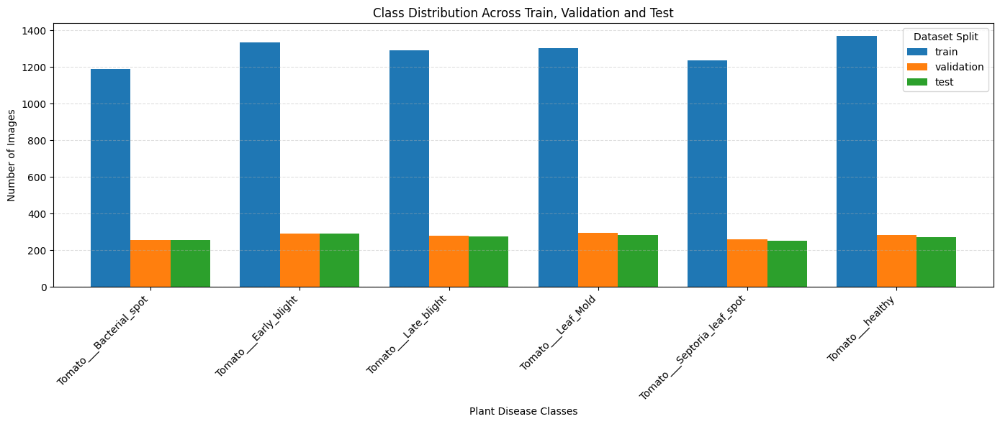

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the existing split manifest
MANIFEST_PATH = (
    "/kaggle/input/datasets/h7alasaleh/splitdata1/split_manifest.csv"
)

df = pd.read_csv(MANIFEST_PATH)

# Count images in each class for each split
class_distribution = (
    df.groupby(["class_name", "split"])
      .size()
      .unstack(fill_value=0)
)

# Keep a consistent split order
class_distribution = class_distribution[
    ["train", "validation", "test"]
]

print("Class Distribution:")
display(class_distribution)

# Plot
ax = class_distribution.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Class Distribution Across Train, Validation and Test")
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

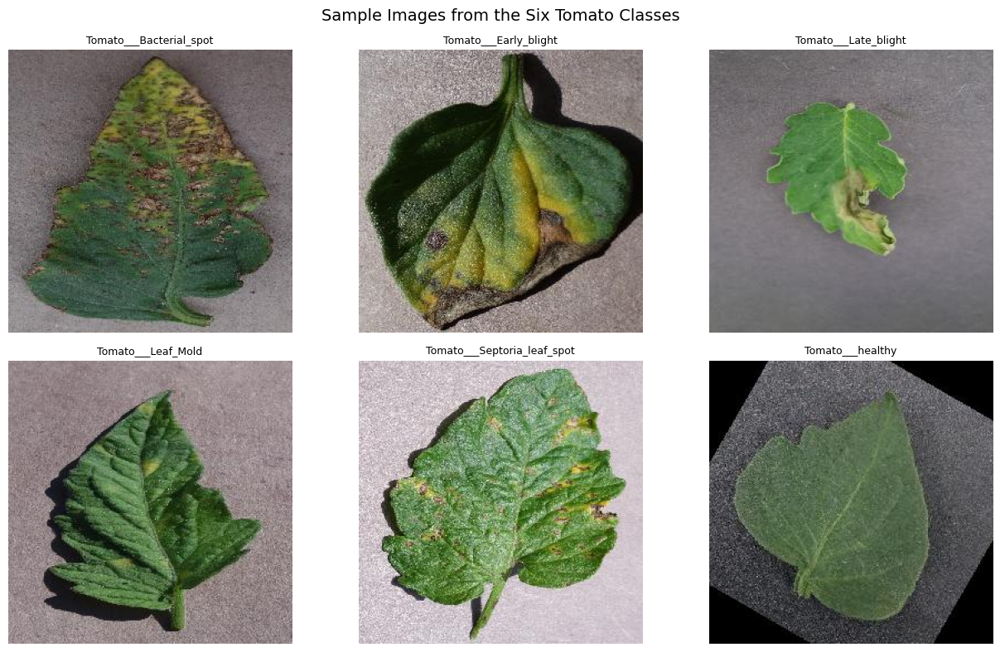

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = sorted(df["class_name"].unique())

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8)
)

axes = axes.flatten()

for i, class_name in enumerate(classes):

    # Select one image from the training set
    sample = df[
        (df["class_name"] == class_name) &
        (df["split"] == "train")
    ].sample(n=1, random_state=42).iloc[0]

    image = Image.open(sample["path"]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(class_name, fontsize=9)
    axes[i].axis("off")

plt.suptitle("Sample Images from the Six Tomato Classes", fontsize=14)
plt.tight_layout()
plt.show()

In [1]:
import os
import random
import numpy as np
import torch
import torchvision

from torchvision import models
from torch import nn

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Feature extraction configuration
BATCH_SIZE = 32
NUM_WORKERS = 2

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# Load pretrained models

resnet_weights = models.ResNet18_Weights.DEFAULT
efficientnet_weights = models.EfficientNet_B0_Weights.DEFAULT
vit_weights = models.ViT_B_16_Weights.DEFAULT

# ResNet18
resnet18 = models.resnet18(weights=resnet_weights)

# EfficientNetB0
efficientnet_b0 = models.efficientnet_b0(
    weights=efficientnet_weights
)

# Vision Transformer
vit_b16 = models.vit_b_16(weights=vit_weights)


# Remove classification heads to obtain feature vectors

resnet18.fc = nn.Identity()

efficientnet_b0.classifier = nn.Identity()

vit_b16.heads = nn.Identity()


# Freeze all model parameters

models_dict = {
    "ResNet18": resnet18,
    "EfficientNetB0": efficientnet_b0,
    "ViT_B16": vit_b16
}

for name, model in models_dict.items():

    for param in model.parameters():
        param.requires_grad = False

    model.to(DEVICE)
    model.eval()

    print(f"{name}: Loaded and frozen")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 151MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 217MB/s] 


ResNet18: Loaded and frozen
EfficientNetB0: Loaded and frozen
ViT_B16: Loaded and frozen


In [3]:
# Feature dimensions
feature_dimensions = {
    "ResNet18": 512,
    "EfficientNetB0": 1280,
    "ViT_B16": 768
}

# Official preprocessing transforms
preprocessing = {
    "ResNet18": resnet_weights.transforms(),
    "EfficientNetB0": efficientnet_weights.transforms(),
    "ViT_B16": vit_weights.transforms()
}

print("Model Configuration:\n")

for name, model in models_dict.items():

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"Model: {name}")
    print("Expected feature dimension:",
          feature_dimensions[name])
    print("Total parameters:", total_params)
    print("Trainable parameters:", trainable_params)
    print("Preprocessing:", preprocessing[name])
    print("-" * 50)

Model Configuration:

Model: ResNet18
Expected feature dimension: 512
Total parameters: 11176512
Trainable parameters: 0
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
--------------------------------------------------
Model: EfficientNetB0
Expected feature dimension: 1280
Total parameters: 4007548
Trainable parameters: 0
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)
--------------------------------------------------
Model: ViT_B16
Expected feature dimension: 768
Total parameters: 85798656
Trainable parameters: 0
Preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
-----------------

In [8]:
import pandas as pd

MANIFEST_PATH = (
    "/kaggle/input/datasets/h7alasaleh/splitdata1/split_manifest.csv"
)

df = pd.read_csv(MANIFEST_PATH)

print("Manifest loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Splits:", df["split"].value_counts().to_dict())

Manifest loaded successfully!
Shape: (11026, 10)
Columns: ['path', 'class_name', 'filename', 'extension', 'filename_marker', 'group_id', 'group_size', 'sha256', 'leakage_group', 'split']
Splits: {'train': 7727, 'validation': 1668, 'test': 1631}


In [9]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd

class PlantDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform, class_to_idx):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["path"]

        image = Image.open(image_path).convert("RGB")

        image = self.transform(image)

        label = self.class_to_idx[row["class_name"]]

        return image, label

In [10]:
# Create a consistent label mapping
classes = sorted(df["class_name"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

# Select 4 training images
sample_df = (
    df[df["split"] == "train"]
    .head(4)
    .reset_index(drop=True)
)

print("Selected images:", len(sample_df))
print("Classes:", class_to_idx)


# Test all three feature extractors
for name, model in models_dict.items():

    sample_dataset = PlantDiseaseDataset(
        dataframe=sample_df,
        transform=preprocessing[name],
        class_to_idx=class_to_idx
    )

    sample_loader = DataLoader(
        sample_dataset,
        batch_size=4,
        shuffle=False,
        num_workers=0
    )

    images, labels = next(iter(sample_loader))

    images = images.to(DEVICE)

    with torch.inference_mode():

        features = model(images)

    print(f"\nModel: {name}")
    print("Input shape:", images.shape)
    print("Output shape:", features.shape)
    print("Expected shape:",
          (4, feature_dimensions[name]))
    print("Labels:", labels.tolist())

Selected images: 4
Classes: {'Tomato___Bacterial_spot': 0, 'Tomato___Early_blight': 1, 'Tomato___Late_blight': 2, 'Tomato___Leaf_Mold': 3, 'Tomato___Septoria_leaf_spot': 4, 'Tomato___healthy': 5}

Model: ResNet18
Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 512])
Expected shape: (4, 512)
Labels: [0, 0, 0, 0]

Model: EfficientNetB0
Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 1280])
Expected shape: (4, 1280)
Labels: [0, 0, 0, 0]

Model: ViT_B16
Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 768])
Expected shape: (4, 768)
Labels: [0, 0, 0, 0]


In [11]:
import os
import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

# Feature extraction settings
FEATURE_BATCH_SIZE = 16
NUM_WORKERS = 2

# Make sure labels exist
df["label"] = df["class_name"].map(class_to_idx)

class PlantDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)

        label = int(row["label"])

        return image, label, idx


print("Dataset size:", len(df))
print("Feature batch size:", FEATURE_BATCH_SIZE)

Dataset size: 11026
Feature batch size: 16


In [12]:
# Create output directory
OUTPUT_DIR = "/kaggle/working/plant_disease_features"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Store extracted features
all_features = {}

for model_name, model in models_dict.items():

    print(f"\nExtracting features using {model_name}...")

    dataset = PlantDataset(
        dataframe=df,
        transform=preprocessing[model_name]
    )

    loader = DataLoader(
        dataset,
        batch_size=FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )

    feature_batches = []
    label_batches = []
    index_batches = []

    model.eval()

    with torch.inference_mode():

        for images, labels, indices in loader:

            images = images.to(DEVICE)

            features = model(images)

            feature_batches.append(
                features.cpu().numpy()
            )

            label_batches.append(
                labels.numpy()
            )

            index_batches.append(
                indices.numpy()
            )

    # Combine all batches
    X_features = np.concatenate(feature_batches, axis=0)
    extracted_labels = np.concatenate(label_batches)
    extracted_indices = np.concatenate(index_batches)

    # Verify image order
    assert np.array_equal(
        extracted_indices,
        np.arange(len(df))
    )

    assert np.array_equal(
        extracted_labels,
        df["label"].to_numpy()
    )

    # Save features
    feature_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_features.npy"
    )

    np.save(feature_path, X_features)

    all_features[model_name] = X_features

    print("Feature shape:", X_features.shape)
    print("Saved to:", feature_path)

    del dataset, loader
    del feature_batches, label_batches, index_batches
    del X_features

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nFeature extraction completed!")


Extracting features using ResNet18...
Feature shape: (11026, 512)
Saved to: /kaggle/working/plant_disease_features/ResNet18_features.npy

Extracting features using EfficientNetB0...
Feature shape: (11026, 1280)
Saved to: /kaggle/working/plant_disease_features/EfficientNetB0_features.npy

Extracting features using ViT_B16...
Feature shape: (11026, 768)
Saved to: /kaggle/working/plant_disease_features/ViT_B16_features.npy

Feature extraction completed!


In [13]:
metadata = df[
    [
        "path",
        "filename",
        "class_name",
        "label",
        "split",
        "group_id",
        "leakage_group"
    ]
].copy()

metadata.to_csv(
    os.path.join(OUTPUT_DIR, "feature_metadata.csv"),
    index=False
)

print("Metadata saved successfully!")
print("Metadata shape:", metadata.shape)

Metadata saved successfully!
Metadata shape: (11026, 7)


In [14]:
import os
import numpy as np
import pandas as pd

OUTPUT_DIR = "/kaggle/working/plant_disease_features"

# Load extracted features
X_resnet = np.load(
    os.path.join(OUTPUT_DIR, "ResNet18_features.npy")
)

X_efficientnet = np.load(
    os.path.join(OUTPUT_DIR, "EfficientNetB0_features.npy")
)

X_vit = np.load(
    os.path.join(OUTPUT_DIR, "ViT_B16_features.npy")
)

# Load metadata
metadata = pd.read_csv(
    os.path.join(OUTPUT_DIR, "feature_metadata.csv")
)

# Scenario 1: ResNet18 + EfficientNetB0
X_scenario1 = np.concatenate(
    [X_resnet, X_efficientnet],
    axis=1
)

# Scenario 2: ViT only
X_scenario2 = X_vit

# Scenario 3: ResNet18 + EfficientNetB0 + ViT
X_scenario3 = np.concatenate(
    [X_resnet, X_efficientnet, X_vit],
    axis=1
)

# Verify dimensions
scenarios = {
    "Scenario_1_CNN_Fusion": X_scenario1,
    "Scenario_2_ViT_Only": X_scenario2,
    "Scenario_3_Hybrid_Fusion": X_scenario3
}

for name, features in scenarios.items():

    print(f"\n{name}")
    print("Shape:", features.shape)
    print("Data type:", features.dtype)
    print("Expected feature dimension:", features.shape[1])

    assert features.shape[0] == len(metadata)


Scenario_1_CNN_Fusion
Shape: (11026, 1792)
Data type: float32
Expected feature dimension: 1792

Scenario_2_ViT_Only
Shape: (11026, 768)
Data type: float32
Expected feature dimension: 768

Scenario_3_Hybrid_Fusion
Shape: (11026, 2560)
Data type: float32
Expected feature dimension: 2560


In [15]:
SCENARIO_DIR = "/kaggle/working/plant_disease_scenarios"

os.makedirs(SCENARIO_DIR, exist_ok=True)

for name, features in scenarios.items():

    save_path = os.path.join(
        SCENARIO_DIR,
        f"{name}.npy"
    )

    np.save(save_path, features)

    print(f"Saved: {save_path}")

Saved: /kaggle/working/plant_disease_scenarios/Scenario_1_CNN_Fusion.npy
Saved: /kaggle/working/plant_disease_scenarios/Scenario_2_ViT_Only.npy
Saved: /kaggle/working/plant_disease_scenarios/Scenario_3_Hybrid_Fusion.npy


In [17]:
# Load labels and split information
y = metadata["label"].to_numpy()
splits = metadata["split"].to_numpy()
groups = metadata["leakage_group"].to_numpy()

# Verify data consistency
for name, features in scenarios.items():

    assert len(features) == len(y)
    assert features.shape[0] == len(splits)
    assert not np.isnan(features).any()
    assert not np.isinf(features).any()

    print(f"{name}: Verification passed")

print("\nTotal samples:", len(y))
print("Train:", np.sum(splits == "train"))
print("Validation:", np.sum(splits == "validation"))
print("Test:", np.sum(splits == "test"))

print("\nAll scenarios are ready!")

Scenario_1_CNN_Fusion: Verification passed
Scenario_2_ViT_Only: Verification passed
Scenario_3_Hybrid_Fusion: Verification passed

Total samples: 11026
Train: 7727
Validation: 1668
Test: 1631

All scenarios are ready!


In [18]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# Select only the original training split
train_mask = metadata["split"].to_numpy() == "train"

# Training labels and leakage groups
y_train = y[train_mask]
groups_train = groups[train_mask]

# Extract training features for each scenario
X_train_scenarios = {
    name: features[train_mask]
    for name, features in scenarios.items()
}

# Verify training data
print("Training samples:", len(y_train))
print("Unique classes:", np.unique(y_train))
print("Unique leakage groups:", len(np.unique(groups_train)))

assert len(y_train) == 7727
assert not pd.isna(groups_train).any()

print("\nTraining data is ready for Cross Validation.")

Training samples: 7727
Unique classes: [0 1 2 3 4 5]
Unique leakage groups: 5525

Training data is ready for Cross Validation.


In [19]:
# Initialize Stratified Group K-Fold
N_SPLITS = 5

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)

# Generate fold indices
folds = list(
    cv.split(
        X=np.zeros(len(y_train)),
        y=y_train,
        groups=groups_train
    )
)

print("Number of folds:", len(folds))

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\nFold {fold_number}")
    print("Training samples:", len(train_idx))
    print("Validation samples:", len(val_idx))

    print(
        "Training classes:",
        np.bincount(y_train[train_idx], minlength=6)
    )

    print(
        "Validation classes:",
        np.bincount(y_train[val_idx], minlength=6)
    )

Number of folds: 5

Fold 1
Training samples: 6162
Validation samples: 1565
Training classes: [ 952 1065 1039 1031  992 1083]
Validation classes: [239 270 254 271 243 288]

Fold 2
Training samples: 6171
Validation samples: 1556
Training classes: [ 953 1063 1032 1046  983 1094]
Validation classes: [238 272 261 256 252 277]

Fold 3
Training samples: 6173
Validation samples: 1554
Training classes: [ 954 1066 1037 1041  986 1089]
Validation classes: [237 269 256 261 249 282]

Fold 4
Training samples: 6195
Validation samples: 1532
Training classes: [ 952 1073 1032 1041  990 1107]
Validation classes: [239 262 261 261 245 264]

Fold 5
Training samples: 6207
Validation samples: 1520
Training classes: [ 953 1073 1032 1049  989 1111]
Validation classes: [238 262 261 253 246 260]


In [20]:
print("Checking group leakage...\n")

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    train_groups = set(groups_train[train_idx])
    val_groups = set(groups_train[val_idx])

    overlap = train_groups.intersection(val_groups)

    print(f"Fold {fold_number}:")
    print("Overlapping groups:", len(overlap))

    assert len(overlap) == 0, (
        f"Group leakage detected in Fold {fold_number}!"
    )

print("\nAll folds passed the group leakage check!")

Checking group leakage...

Fold 1:
Overlapping groups: 0
Fold 2:
Overlapping groups: 0
Fold 3:
Overlapping groups: 0
Fold 4:
Overlapping groups: 0
Fold 5:
Overlapping groups: 0

All folds passed the group leakage check!


In [22]:
# Recreate class mappings from metadata

classes = sorted(metadata["class_name"].unique())

class_to_idx = {
    class_name: idx
    for idx, class_name in enumerate(classes)
}

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

class_names = [
    idx_to_class[i]
    for i in range(len(idx_to_class))
]

print("Class mapping:")
for idx, name in idx_to_class.items():
    print(f"{idx}: {name}")

print("\nNumber of classes:", len(class_names))

Class mapping:
0: Tomato___Bacterial_spot
1: Tomato___Early_blight
2: Tomato___Late_blight
3: Tomato___Leaf_Mold
4: Tomato___Septoria_leaf_spot
5: Tomato___healthy

Number of classes: 6


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

classifiers = {

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            metric="minkowski",
            p=2,
            n_jobs=-1
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])
}

print("Classifier configuration completed!")

for name, model in classifiers.items():
    print(f"{name}: {model}")

Classifier configuration completed!
SVM: Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC())])
KNN: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 KNeighborsClassifier(n_jobs=-1, weights='distance'))])
Random Forest: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
Logistic Regression: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])


In [24]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import time
import pandas as pd
import numpy as np

results = []

print("Evaluation environment is ready.")
print("Scenarios:", len(scenarios))
print("Classifiers:", len(classifiers))
print("Folds:", len(folds))
print("Expected experiments:", len(scenarios) * len(classifiers))

Evaluation environment is ready.
Scenarios: 3
Classifiers: 4
Folds: 5
Expected experiments: 12


In [25]:
# Scenario 1 + SVM: 5-Fold Cross Validation

scenario_name = "Scenario_1_CNN_Fusion"
classifier_name = "SVM"

X = X_train_scenarios[scenario_name]
model = classifiers[classifier_name]

print(f"Starting: {scenario_name} + {classifier_name}")
print("Feature shape:", X.shape)

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    start_time = time.time()

    # Split data for this fold
    X_fold_train = X[train_idx]
    X_fold_val = X[val_idx]

    y_fold_train = y_train[train_idx]
    y_fold_val = y_train[val_idx]

    # Create a fresh model for each fold
    fold_model = clone(model)

    # Training
    fold_model.fit(X_fold_train, y_fold_train)

    # Prediction
    y_pred = fold_model.predict(X_fold_val)

    # Evaluation
    accuracy = accuracy_score(y_fold_val, y_pred)

    precision = precision_score(
        y_fold_val, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_fold_val, y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_fold_val, y_pred,
        average="macro",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_fold_val, y_pred,
        average="weighted",
        zero_division=0
    )

    elapsed_time = time.time() - start_time

    # Save results
    results.append({
        "Scenario": scenario_name,
        "Classifier": classifier_name,
        "Fold": fold_number,
        "Accuracy": accuracy,
        "Precision_Macro": precision,
        "Recall_Macro": recall,
        "F1_Macro": f1_macro,
        "F1_Weighted": f1_weighted,
        "Time_Seconds": elapsed_time
    })

    print(f"\nFold {fold_number} completed")
    print(f"Accuracy:       {accuracy:.4f}")
    print(f"Precision:      {precision:.4f}")
    print(f"Recall:         {recall:.4f}")
    print(f"F1 Macro:       {f1_macro:.4f}")
    print(f"F1 Weighted:    {f1_weighted:.4f}")
    print(f"Time:           {elapsed_time:.2f} seconds")

print("\nScenario 1 + SVM completed successfully!")

Starting: Scenario_1_CNN_Fusion + SVM
Feature shape: (7727, 1792)

Fold 1 completed
Accuracy:       0.9597
Precision:      0.9597
Recall:         0.9596
F1 Macro:       0.9596
F1 Weighted:    0.9596
Time:           27.20 seconds

Fold 2 completed
Accuracy:       0.9627
Precision:      0.9629
Recall:         0.9633
F1 Macro:       0.9627
F1 Weighted:    0.9626
Time:           27.70 seconds

Fold 3 completed
Accuracy:       0.9723
Precision:      0.9730
Recall:         0.9724
F1 Macro:       0.9722
F1 Weighted:    0.9723
Time:           27.75 seconds

Fold 4 completed
Accuracy:       0.9700
Precision:      0.9701
Recall:         0.9698
F1 Macro:       0.9698
F1 Weighted:    0.9698
Time:           27.46 seconds

Fold 5 completed
Accuracy:       0.9678
Precision:      0.9679
Recall:         0.9682
F1 Macro:       0.9680
F1 Weighted:    0.9676
Time:           27.88 seconds

Scenario 1 + SVM completed successfully!


In [27]:
import os
import numpy as np
import pandas as pd
import time

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Results directory
RESULTS_DIR = "/kaggle/working/plant_disease_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Ensure results list exists
if "results" not in globals():
    results = []

def save_results():

    results_df = pd.DataFrame(results)

    # Save all fold results
    results_df.to_csv(
        os.path.join(RESULTS_DIR, "all_fold_results.csv"),
        index=False
    )

    # Calculate summary statistics
    summary = (
        results_df
        .groupby(["Scenario", "Classifier"])
        .agg({
            "Accuracy": ["mean", "std"],
            "Precision_Macro": ["mean", "std"],
            "Recall_Macro": ["mean", "std"],
            "F1_Macro": ["mean", "std"],
            "F1_Weighted": ["mean", "std"],
            "Time_Seconds": ["mean", "sum"]
        })
    )

    summary.columns = [
        f"{metric}_{stat}"
        for metric, stat in summary.columns
    ]

    summary = summary.reset_index()

    summary.to_csv(
        os.path.join(RESULTS_DIR, "experiment_summary.csv"),
        index=False
    )

    return results_df, summary


def run_scenario(scenario_name):

    X = X_train_scenarios[scenario_name]

    print("=" * 65)
    print(f"STARTING {scenario_name}")
    print("=" * 65)
    print("Feature shape:", X.shape)
    print("Number of classifiers:", len(classifiers))
    print("Number of folds:", len(folds))

    for classifier_name, model in classifiers.items():

        print("\n" + "-" * 50)
        print(f"Classifier: {classifier_name}")
        print("-" * 50)

        for fold_number, (train_idx, val_idx) in enumerate(
            folds, start=1
        ):

            # Avoid repeating completed folds
            already_completed = any(
                r["Scenario"] == scenario_name
                and r["Classifier"] == classifier_name
                and r["Fold"] == fold_number
                for r in results
            )

            if already_completed:
                print(f"Fold {fold_number}: Already completed. Skipping.")
                continue

            start_time = time.time()

            # Split fold data
            X_fold_train = X[train_idx]
            X_fold_val = X[val_idx]

            y_fold_train = y_train[train_idx]
            y_fold_val = y_train[val_idx]

            # Fresh model for each fold
            fold_model = clone(model)

            # Training
            fold_model.fit(X_fold_train, y_fold_train)

            # Prediction
            y_pred = fold_model.predict(X_fold_val)

            # Metrics
            accuracy = accuracy_score(y_fold_val, y_pred)

            precision = precision_score(
                y_fold_val,
                y_pred,
                average="macro",
                zero_division=0
            )

            recall = recall_score(
                y_fold_val,
                y_pred,
                average="macro",
                zero_division=0
            )

            f1_macro = f1_score(
                y_fold_val,
                y_pred,
                average="macro",
                zero_division=0
            )

            f1_weighted = f1_score(
                y_fold_val,
                y_pred,
                average="weighted",
                zero_division=0
            )

            elapsed_time = time.time() - start_time

            # Store fold results
            results.append({
                "Scenario": scenario_name,
                "Classifier": classifier_name,
                "Fold": fold_number,
                "Accuracy": accuracy,
                "Precision_Macro": precision,
                "Recall_Macro": recall,
                "F1_Macro": f1_macro,
                "F1_Weighted": f1_weighted,
                "Time_Seconds": elapsed_time
            })

            # Save immediately after every fold
            save_results()

            print(
                f"Fold {fold_number}/5 | "
                f"Accuracy: {accuracy:.4f} | "
                f"Macro F1: {f1_macro:.4f} | "
                f"Time: {elapsed_time:.2f}s"
            )

        print(f"\n{classifier_name} completed.")

    # Final scenario summary
    results_df, summary = save_results()

    scenario_summary = summary[
        summary["Scenario"] == scenario_name
    ]

    print("\n" + "=" * 65)
    print(f"{scenario_name} COMPLETED")
    print("=" * 65)

    display(
        scenario_summary[
            [
                "Classifier",
                "Accuracy_mean",
                "Accuracy_std",
                "F1_Macro_mean",
                "F1_Macro_std",
                "Time_Seconds_sum"
            ]
        ].round(4)
    )

    print("\nResults saved successfully!")
    print("Directory:", RESULTS_DIR)

In [28]:
run_scenario("Scenario_1_CNN_Fusion")

STARTING Scenario_1_CNN_Fusion
Feature shape: (7727, 1792)
Number of classifiers: 4
Number of folds: 5

--------------------------------------------------
Classifier: SVM
--------------------------------------------------
Fold 1: Already completed. Skipping.
Fold 2: Already completed. Skipping.
Fold 3: Already completed. Skipping.
Fold 4: Already completed. Skipping.
Fold 5: Already completed. Skipping.

SVM completed.

--------------------------------------------------
Classifier: KNN
--------------------------------------------------
Fold 1/5 | Accuracy: 0.9061 | Macro F1: 0.9040 | Time: 0.85s
Fold 2/5 | Accuracy: 0.9062 | Macro F1: 0.9038 | Time: 0.70s
Fold 3/5 | Accuracy: 0.9080 | Macro F1: 0.9062 | Time: 0.70s
Fold 4/5 | Accuracy: 0.9230 | Macro F1: 0.9216 | Time: 0.69s
Fold 5/5 | Accuracy: 0.9099 | Macro F1: 0.9086 | Time: 0.69s

KNN completed.

--------------------------------------------------
Classifier: Random Forest
--------------------------------------------------
Fold 1/5

,Classifier,Accuracy_mean,Accuracy_std,F1_Macro_mean,F1_Macro_std,Time_Seconds_sum
0,KNN,0.9106,0.0071,0.9088,0.0074,3.6297
1,Logistic Regression,0.9673,0.0065,0.9673,0.0066,11.2869
2,Random Forest,0.9149,0.0106,0.9137,0.0107,181.7314
3,SVM,0.9665,0.0052,0.9665,0.0052,137.9799



Results saved successfully!
Directory: /kaggle/working/plant_disease_results


In [29]:
run_scenario("Scenario_2_ViT_Only")

STARTING Scenario_2_ViT_Only
Feature shape: (7727, 768)
Number of classifiers: 4
Number of folds: 5

--------------------------------------------------
Classifier: SVM
--------------------------------------------------
Fold 1/5 | Accuracy: 0.9700 | Macro F1: 0.9700 | Time: 9.07s
Fold 2/5 | Accuracy: 0.9775 | Macro F1: 0.9774 | Time: 9.07s
Fold 3/5 | Accuracy: 0.9788 | Macro F1: 0.9785 | Time: 9.14s
Fold 4/5 | Accuracy: 0.9765 | Macro F1: 0.9764 | Time: 8.96s
Fold 5/5 | Accuracy: 0.9645 | Macro F1: 0.9647 | Time: 8.93s

SVM completed.

--------------------------------------------------
Classifier: KNN
--------------------------------------------------
Fold 1/5 | Accuracy: 0.8837 | Macro F1: 0.8809 | Time: 0.31s
Fold 2/5 | Accuracy: 0.8895 | Macro F1: 0.8870 | Time: 0.31s
Fold 3/5 | Accuracy: 0.8970 | Macro F1: 0.8949 | Time: 0.31s
Fold 4/5 | Accuracy: 0.8910 | Macro F1: 0.8882 | Time: 0.30s
Fold 5/5 | Accuracy: 0.8961 | Macro F1: 0.8940 | Time: 0.30s

KNN completed.

-------------------

,Classifier,Accuracy_mean,Accuracy_std,F1_Macro_mean,F1_Macro_std,Time_Seconds_sum
4,KNN,0.8915,0.0054,0.8890,0.0057,1.5246
5,Logistic Regression,0.9758,0.0046,0.9757,0.0044,7.3463
6,Random Forest,0.8926,0.0104,0.8914,0.0105,117.4899
7,SVM,0.9734,0.0061,0.9734,0.0059,45.1679



Results saved successfully!
Directory: /kaggle/working/plant_disease_results


In [30]:
run_scenario("Scenario_3_Hybrid_Fusion")

STARTING Scenario_3_Hybrid_Fusion
Feature shape: (7727, 2560)
Number of classifiers: 4
Number of folds: 5

--------------------------------------------------
Classifier: SVM
--------------------------------------------------
Fold 1/5 | Accuracy: 0.9744 | Macro F1: 0.9745 | Time: 47.56s
Fold 2/5 | Accuracy: 0.9769 | Macro F1: 0.9769 | Time: 47.90s
Fold 3/5 | Accuracy: 0.9833 | Macro F1: 0.9832 | Time: 48.06s
Fold 4/5 | Accuracy: 0.9811 | Macro F1: 0.9810 | Time: 48.15s
Fold 5/5 | Accuracy: 0.9789 | Macro F1: 0.9792 | Time: 47.78s

SVM completed.

--------------------------------------------------
Classifier: KNN
--------------------------------------------------
Fold 1/5 | Accuracy: 0.9182 | Macro F1: 0.9165 | Time: 1.02s
Fold 2/5 | Accuracy: 0.9203 | Macro F1: 0.9185 | Time: 1.02s
Fold 3/5 | Accuracy: 0.9273 | Macro F1: 0.9259 | Time: 1.01s
Fold 4/5 | Accuracy: 0.9262 | Macro F1: 0.9248 | Time: 1.00s
Fold 5/5 | Accuracy: 0.9237 | Macro F1: 0.9226 | Time: 0.98s

KNN completed.

--------

,Classifier,Accuracy_mean,Accuracy_std,F1_Macro_mean,F1_Macro_std,Time_Seconds_sum
8,KNN,0.9231,0.0039,0.9217,0.0040,5.0367
9,Logistic Regression,0.9819,0.0041,0.9818,0.0040,11.8124
10,Random Forest,0.9247,0.0125,0.9237,0.0127,214.1126
11,SVM,0.9789,0.0035,0.9789,0.0034,239.4679



Results saved successfully!
Directory: /kaggle/working/plant_disease_results


In [31]:
import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/plant_disease_results"

fold_results = pd.read_csv(
    os.path.join(RESULTS_DIR, "all_fold_results.csv")
)

summary = pd.read_csv(
    os.path.join(RESULTS_DIR, "experiment_summary.csv")
)

print("Total fold records:", len(fold_results))
print("Unique experiments:", 
      fold_results.groupby(["Scenario", "Classifier"]).ngroups)

print("\nRecords per experiment:")
print(
    fold_results.groupby(["Scenario", "Classifier"])
    .size()
)

print("\nSaved files:")
for filename in os.listdir(RESULTS_DIR):
    print(filename)

assert len(fold_results) == 60
assert fold_results.groupby(["Scenario", "Classifier"]).ngroups == 12
assert (fold_results.groupby(["Scenario", "Classifier"]).size() == 5).all()

print("\nAll 12 experiments and 60 fold results verified!")

Total fold records: 60
Unique experiments: 12

Records per experiment:
Scenario                  Classifier         
Scenario_1_CNN_Fusion     KNN                    5
                          Logistic Regression    5
                          Random Forest          5
                          SVM                    5
Scenario_2_ViT_Only       KNN                    5
                          Logistic Regression    5
                          Random Forest          5
                          SVM                    5
Scenario_3_Hybrid_Fusion  KNN                    5
                          Logistic Regression    5
                          Random Forest          5
                          SVM                    5
dtype: int64

Saved files:
experiment_summary.csv
all_fold_results.csv

All 12 experiments and 60 fold results verified!


In [32]:
import os
import numpy as np
import pandas as pd
import time

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load metadata
metadata = pd.read_csv(
    "/kaggle/working/plant_disease_features/feature_metadata.csv"
)

# Load feature scenarios
scenarios = {
    "Scenario_1_CNN_Fusion": np.load(
        "/kaggle/working/plant_disease_scenarios/Scenario_1_CNN_Fusion.npy"
    ),
    "Scenario_2_ViT_Only": np.load(
        "/kaggle/working/plant_disease_scenarios/Scenario_2_ViT_Only.npy"
    ),
    "Scenario_3_Hybrid_Fusion": np.load(
        "/kaggle/working/plant_disease_scenarios/Scenario_3_Hybrid_Fusion.npy"
    )
}

# Check split names
print("Available splits:", metadata["split"].unique())

# Create masks
train_mask = metadata["split"].to_numpy() == "train"
val_mask = metadata["split"].to_numpy() == "validation"

# Labels
y = metadata["label"].to_numpy()

y_train = y[train_mask]
y_val = y[val_mask]

# Split features for all scenarios
X_train_scenarios = {
    name: X[train_mask]
    for name, X in scenarios.items()
}

X_val_scenarios = {
    name: X[val_mask]
    for name, X in scenarios.items()
}

# Verify dimensions
print("\nTrain samples:", len(y_train))
print("Validation samples:", len(y_val))

for name in scenarios:
    print(
        f"{name}: "
        f"Train = {X_train_scenarios[name].shape}, "
        f"Validation = {X_val_scenarios[name].shape}"
    )

# Verify class distribution
print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Available splits: ['train' 'validation' 'test']

Train samples: 7727
Validation samples: 1668
Scenario_1_CNN_Fusion: Train = (7727, 1792), Validation = (1668, 1792)
Scenario_2_ViT_Only: Train = (7727, 768), Validation = (1668, 768)
Scenario_3_Hybrid_Fusion: Train = (7727, 2560), Validation = (1668, 2560)

Validation class distribution:
0    255
1    293
2    281
3    295
4    259
5    285
Name: count, dtype: int64


In [33]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import time
import os

# Scenario 1: CNN Fusion
scenario_name = "Scenario_1_CNN_Fusion"

X_train = X_train_scenarios[scenario_name]
X_val = X_val_scenarios[scenario_name]

scenario_results = []

print(f"Starting {scenario_name}")
print(f"Train shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")

for classifier_name, classifier_template in classifiers.items():

    print(f"\nTraining: {classifier_name}")

    model = clone(classifier_template)

    # Training
    train_start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - train_start

    # Prediction
    predict_start = time.time()
    y_pred = model.predict(X_val)
    predict_time = time.time() - predict_start

    # Evaluation
    metrics = {
        "Scenario": scenario_name,
        "Classifier": classifier_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision_Macro": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_val, y_pred, average="weighted", zero_division=0
        ),
        "Training_Time": train_time,
        "Prediction_Time": predict_time
    }

    scenario_results.append(metrics)

    print(
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"F1 Macro: {metrics['F1_Macro']:.4f} | "
        f"Train Time: {train_time:.2f}s"
    )

# Save results
results_dir = "/kaggle/working/plant_disease_results"
os.makedirs(results_dir, exist_ok=True)

scenario_df = pd.DataFrame(scenario_results)

results_path = os.path.join(
    results_dir,
    "validation_scenario_1.csv"
)

scenario_df.to_csv(results_path, index=False)

print("\nScenario 1 Results:")
display(
    scenario_df.sort_values("F1_Macro", ascending=False)
)

print(f"\nResults saved to: {results_path}")


Starting Scenario_1_CNN_Fusion
Train shape: (7727, 1792)
Validation shape: (1668, 1792)

Training: SVM
Accuracy: 0.9808 | F1 Macro: 0.9811 | Train Time: 28.13s

Training: KNN
Accuracy: 0.9365 | F1 Macro: 0.9356 | Train Time: 0.18s

Training: Random Forest
Accuracy: 0.9263 | F1 Macro: 0.9259 | Train Time: 47.61s

Training: Logistic Regression
Accuracy: 0.9754 | F1 Macro: 0.9755 | Train Time: 2.17s

Scenario 1 Results:


,Scenario,Classifier,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,Training_Time,Prediction_Time
0,Scenario_1_CNN_Fusion,SVM,0.980815,0.981025,0.981278,0.981069,0.980733,28.134836,13.532461
3,Scenario_1_CNN_Fusion,Logistic Regression,0.975420,0.975290,0.975926,0.975464,0.975258,2.172799,0.037137
1,Scenario_1_CNN_Fusion,KNN,0.936451,0.937785,0.937755,0.935631,0.935308,0.183047,0.676679
2,Scenario_1_CNN_Fusion,Random Forest,0.926259,0.925874,0.926139,0.925891,0.925935,47.612943,0.119726



Results saved to: /kaggle/working/plant_disease_results/validation_scenario_1.csv


In [34]:

# Scenario 2: ViT Only

scenario_name = "Scenario_2_ViT_Only"

X_train = X_train_scenarios[scenario_name]
X_val = X_val_scenarios[scenario_name]

scenario_results = []

print(f"Starting {scenario_name}")
print(f"Train shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")

for classifier_name, classifier_template in classifiers.items():

    print(f"\nTraining: {classifier_name}")

    model = clone(classifier_template)

    # Training
    train_start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - train_start

    # Prediction
    predict_start = time.time()
    y_pred = model.predict(X_val)
    predict_time = time.time() - predict_start

    # Evaluation
    metrics = {
        "Scenario": scenario_name,
        "Classifier": classifier_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision_Macro": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_val, y_pred, average="weighted", zero_division=0
        ),
        "Training_Time": train_time,
        "Prediction_Time": predict_time
    }

    scenario_results.append(metrics)

    print(
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"F1 Macro: {metrics['F1_Macro']:.4f} | "
        f"Train Time: {train_time:.2f}s"
    )

# Save results
scenario_df = pd.DataFrame(scenario_results)

results_path = os.path.join(
    results_dir,
    "validation_scenario_2.csv"
)

scenario_df.to_csv(results_path, index=False)

print("\nScenario 2 Results:")
display(
    scenario_df.sort_values("F1_Macro", ascending=False)
)

print(f"\nResults saved to: {results_path}")


Starting Scenario_2_ViT_Only
Train shape: (7727, 768)
Validation shape: (1668, 768)

Training: SVM
Accuracy: 0.9880 | F1 Macro: 0.9882 | Train Time: 7.71s

Training: KNN
Accuracy: 0.9005 | F1 Macro: 0.8982 | Train Time: 0.07s

Training: Random Forest
Accuracy: 0.9035 | F1 Macro: 0.9024 | Train Time: 30.31s

Training: Logistic Regression
Accuracy: 0.9766 | F1 Macro: 0.9766 | Train Time: 1.46s

Scenario 2 Results:


,Scenario,Classifier,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,Training_Time,Prediction_Time
0,Scenario_2_ViT_Only,SVM,0.988010,0.988045,0.988300,0.988154,0.987987,7.707590,4.775383
3,Scenario_2_ViT_Only,Logistic Regression,0.976619,0.976526,0.976790,0.976604,0.976563,1.460334,0.011163
2,Scenario_2_ViT_Only,Random Forest,0.903477,0.902864,0.902967,0.902381,0.902626,30.314854,0.117754
1,Scenario_2_ViT_Only,KNN,0.900480,0.904357,0.902080,0.898226,0.898240,0.070004,0.300635



Results saved to: /kaggle/working/plant_disease_results/validation_scenario_2.csv


In [35]:

# Scenario 3: Hybrid Fusion

scenario_name = "Scenario_3_Hybrid_Fusion"

X_train = X_train_scenarios[scenario_name]
X_val = X_val_scenarios[scenario_name]

scenario_results = []

print(f"Starting {scenario_name}")
print(f"Train shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")

for classifier_name, classifier_template in classifiers.items():

    print(f"\nTraining: {classifier_name}")

    model = clone(classifier_template)

    # Training
    train_start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - train_start

    # Prediction
    predict_start = time.time()
    y_pred = model.predict(X_val)
    predict_time = time.time() - predict_start

    # Evaluation
    metrics = {
        "Scenario": scenario_name,
        "Classifier": classifier_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision_Macro": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_val, y_pred, average="weighted", zero_division=0
        ),
        "Training_Time": train_time,
        "Prediction_Time": predict_time
    }

    scenario_results.append(metrics)

    print(
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"F1 Macro: {metrics['F1_Macro']:.4f} | "
        f"Train Time: {train_time:.2f}s"
    )

# Save results
scenario_df = pd.DataFrame(scenario_results)

results_path = os.path.join(
    results_dir,
    "validation_scenario_3.csv"
)

scenario_df.to_csv(results_path, index=False)

print("\nScenario 3 Results:")
display(
    scenario_df.sort_values("F1_Macro", ascending=False)
)

print(f"\nResults saved to: {results_path}")


Starting Scenario_3_Hybrid_Fusion
Train shape: (7727, 2560)
Validation shape: (1668, 2560)

Training: SVM
Accuracy: 0.9868 | F1 Macro: 0.9869 | Train Time: 47.28s

Training: KNN
Accuracy: 0.9460 | F1 Macro: 0.9454 | Train Time: 0.28s

Training: Random Forest
Accuracy: 0.9305 | F1 Macro: 0.9300 | Train Time: 55.87s

Training: Logistic Regression
Accuracy: 0.9886 | F1 Macro: 0.9888 | Train Time: 2.83s

Scenario 3 Results:


,Scenario,Classifier,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,Training_Time,Prediction_Time
3,Scenario_3_Hybrid_Fusion,Logistic Regression,0.988609,0.988751,0.988862,0.988797,0.988591,2.830520,0.088773
0,Scenario_3_Hybrid_Fusion,SVM,0.986811,0.986869,0.987069,0.986910,0.986763,47.284390,20.550884
1,Scenario_3_Hybrid_Fusion,KNN,0.946043,0.947263,0.947582,0.945368,0.945037,0.277235,0.999245
2,Scenario_3_Hybrid_Fusion,Random Forest,0.930456,0.930073,0.930658,0.930018,0.929915,55.872859,0.118275



Results saved to: /kaggle/working/plant_disease_results/validation_scenario_3.csv


In [36]:

import os
import pandas as pd

# Results directory
results_dir = "/kaggle/working/plant_disease_results"

# Load the three scenario results
scenario_files = [
    "validation_scenario_1.csv",
    "validation_scenario_2.csv",
    "validation_scenario_3.csv"
]

all_results = []

for file_name in scenario_files:
    file_path = os.path.join(results_dir, file_name)

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Missing file: {file_path}")

    df = pd.read_csv(file_path)
    all_results.append(df)

# Combine all scenarios
comparison_df = pd.concat(all_results, ignore_index=True)

# Sort by F1 Macro
comparison_df = comparison_df.sort_values(
    by="F1_Macro",
    ascending=False
).reset_index(drop=True)

# Save complete comparison
all_path = os.path.join(
    results_dir,
    "validation_comparison_all.csv"
)

comparison_df.to_csv(all_path, index=False)

# Create F1 Macro comparison table
f1_comparison = comparison_df.pivot(
    index="Classifier",
    columns="Scenario",
    values="F1_Macro"
)

f1_comparison = f1_comparison[
    [
        "Scenario_1_CNN_Fusion",
        "Scenario_2_ViT_Only",
        "Scenario_3_Hybrid_Fusion"
    ]
]

f1_comparison["Best_Scenario"] = (
    f1_comparison.idxmax(axis=1)
)

f1_path = os.path.join(
    results_dir,
    "validation_comparison_F1_Macro.csv"
)

f1_comparison.to_csv(f1_path)

# Create Accuracy comparison table
accuracy_comparison = comparison_df.pivot(
    index="Classifier",
    columns="Scenario",
    values="Accuracy"
)

accuracy_comparison = accuracy_comparison[
    [
        "Scenario_1_CNN_Fusion",
        "Scenario_2_ViT_Only",
        "Scenario_3_Hybrid_Fusion"
    ]
]

accuracy_comparison["Best_Scenario"] = (
    accuracy_comparison.idxmax(axis=1)
)

accuracy_path = os.path.join(
    results_dir,
    "validation_comparison_Accuracy.csv"
)

accuracy_comparison.to_csv(accuracy_path)

# Display results
print("========== COMPLETE VALIDATION COMPARISON ==========")
display(comparison_df)

print("\n========== F1 MACRO COMPARISON ==========")
display(f1_comparison)

print("\n========== ACCURACY COMPARISON ==========")
display(accuracy_comparison)

# Verify records
print("\n========== VERIFICATION ==========")
print("Total experiments:", len(comparison_df))
print("Unique scenarios:", comparison_df["Scenario"].nunique())
print("Unique classifiers:", comparison_df["Classifier"].nunique())

print("\nSaved files:")
print(all_path)
print(f1_path)
print(accuracy_path)


========== COMPLETE VALIDATION COMPARISON ==========


,Scenario,Classifier,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,Training_Time,Prediction_Time
0,Scenario_3_Hybrid_Fusion,Logistic Regression,0.988609,0.988751,0.988862,0.988797,0.988591,2.830520,0.088773
1,Scenario_2_ViT_Only,SVM,0.988010,0.988045,0.988300,0.988154,0.987987,7.707590,4.775383
2,Scenario_3_Hybrid_Fusion,SVM,0.986811,0.986869,0.987069,0.986910,0.986763,47.284390,20.550884
3,Scenario_1_CNN_Fusion,SVM,0.980815,0.981025,0.981278,0.981069,0.980733,28.134836,13.532461
4,Scenario_2_ViT_Only,Logistic Regression,0.976619,0.976526,0.976790,0.976604,0.976563,1.460334,0.011163
5,Scenario_1_CNN_Fusion,Logistic Regression,0.975420,0.975290,0.975926,0.975464,0.975258,2.172799,0.037137
6,Scenario_3_Hybrid_Fusion,KNN,0.946043,0.947263,0.947582,0.945368,0.945037,0.277235,0.999245
7,Scenario_1_CNN_Fusion,KNN,0.936451,0.937785,0.937755,0.935631,0.935308,0.183047,0.676679
8,Scenario_3_Hybrid_Fusion,Random Forest,0.930456,0.930073,0.930658,0.930018,0.929915,55.872859,0.118275
9,Scenario_1_CNN_Fusion,Random Forest,0.926259,0.925874,0.926139,0.925891,0.925935,47.612943,0.119726



========== F1 MACRO COMPARISON ==========


Scenario,Scenario_1_CNN_Fusion,Scenario_2_ViT_Only,Scenario_3_Hybrid_Fusion,Best_Scenario
Classifier,,,,
KNN,0.935631,0.898226,0.945368,Scenario_3_Hybrid_Fusion
Logistic Regression,0.975464,0.976604,0.988797,Scenario_3_Hybrid_Fusion
Random Forest,0.925891,0.902381,0.930018,Scenario_3_Hybrid_Fusion
SVM,0.981069,0.988154,0.986910,Scenario_2_ViT_Only



========== ACCURACY COMPARISON ==========


Scenario,Scenario_1_CNN_Fusion,Scenario_2_ViT_Only,Scenario_3_Hybrid_Fusion,Best_Scenario
Classifier,,,,
KNN,0.936451,0.900480,0.946043,Scenario_3_Hybrid_Fusion
Logistic Regression,0.975420,0.976619,0.988609,Scenario_3_Hybrid_Fusion
Random Forest,0.926259,0.903477,0.930456,Scenario_3_Hybrid_Fusion
SVM,0.980815,0.988010,0.986811,Scenario_2_ViT_Only



========== VERIFICATION ==========
Total experiments: 12
Unique scenarios: 3
Unique classifiers: 4

Saved files:
/kaggle/working/plant_disease_results/validation_comparison_all.csv
/kaggle/working/plant_disease_results/validation_comparison_F1_Macro.csv
/kaggle/working/plant_disease_results/validation_comparison_Accuracy.csv


In [37]:

# Final model: Scenario 3 + Logistic Regression

scenario_name = "Scenario_3_Hybrid_Fusion"

# Prepare Train + Validation
train_val_mask = metadata["split"].isin(
    ["train", "validation"]
).to_numpy()

test_mask = metadata["split"].to_numpy() == "test"

X_all = scenarios[scenario_name]

X_train_final = X_all[train_val_mask]
y_train_final = y[train_val_mask]

X_test_final = X_all[test_mask]
y_test_final = y[test_mask]

# Verify dimensions
print("Final Training Set:")
print("X:", X_train_final.shape)
print("y:", y_train_final.shape)

print("\nFinal Test Set:")
print("X:", X_test_final.shape)
print("y:", y_test_final.shape)

print("\nTotal training samples:", len(y_train_final))
print("Total test samples:", len(y_test_final))

# Verify class distribution
print("\nTraining class distribution:")
print(pd.Series(y_train_final).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test_final).value_counts().sort_index())


Final Training Set:
X: (9395, 2560)
y: (9395,)

Final Test Set:
X: (1631, 2560)
y: (1631,)

Total training samples: 9395
Total test samples: 1631

Training class distribution:
0    1446
1    1628
2    1574
3    1597
4    1494
5    1656
Name: count, dtype: int64

Test class distribution:
0    256
1    292
2    277
3    285
4    251
5    270
Name: count, dtype: int64


Starting Final Training...
Final Training completed in 3.98 seconds

Evaluating on Test Set...

========== FINAL TEST RESULTS ==========
Model: Scenario_3_Hybrid_Fusion + Logistic Regression
Test_Samples: 1631
Accuracy: 0.989577
Precision_Macro: 0.989644
Recall_Macro: 0.989617
F1_Macro: 0.989620
F1_Weighted: 0.989582
Training_Time: 3.980135
Prediction_Time: 0.087456

========== CLASSIFICATION REPORT ==========


,precision,recall,f1-score,support
Tomato___Bacterial_spot,0.996109,1.000000,0.998051,256.000000
Tomato___Early_blight,0.979661,0.989726,0.984668,292.000000
Tomato___Late_blight,0.985455,0.978339,0.981884,277.000000
Tomato___Leaf_Mold,0.996479,0.992982,0.994728,285.000000
Tomato___Septoria_leaf_spot,0.980159,0.984064,0.982107,251.000000
Tomato___healthy,1.000000,0.992593,0.996283,270.000000
accuracy,0.989577,0.989577,0.989577,0.989577
macro avg,0.989644,0.989617,0.989620,1631.000000
weighted avg,0.989609,0.989577,0.989582,1631.000000


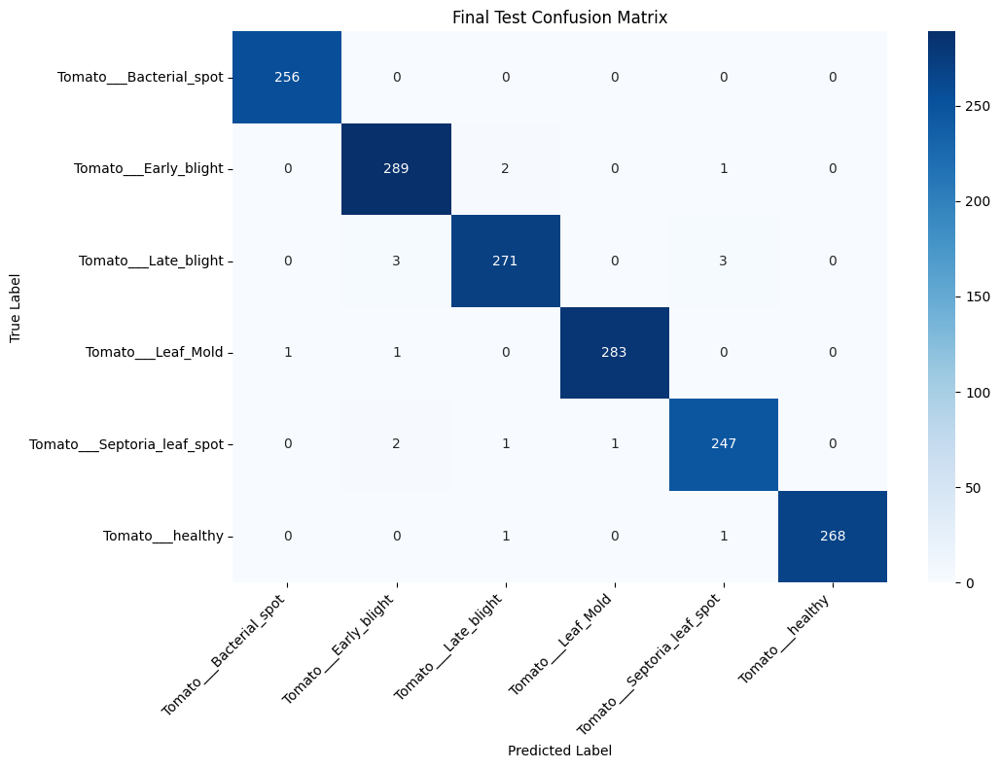


All final evaluation files saved successfully!


In [38]:

import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# =====================================
# 1. Create Final Model
# =====================================

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# =====================================
# 2. Final Training
# =====================================

print("Starting Final Training...")

train_start = time.time()

final_model.fit(X_train_final, y_train_final)

final_training_time = time.time() - train_start

print(f"Final Training completed in {final_training_time:.2f} seconds")

# =====================================
# 3. Test Prediction
# =====================================

print("\nEvaluating on Test Set...")

predict_start = time.time()

y_test_pred = final_model.predict(X_test_final)

test_prediction_time = time.time() - predict_start

# =====================================
# 4. Calculate Metrics
# =====================================

test_metrics = {
    "Model": "Scenario_3_Hybrid_Fusion + Logistic Regression",
    "Test_Samples": len(y_test_final),
    "Accuracy": accuracy_score(y_test_final, y_test_pred),
    "Precision_Macro": precision_score(
        y_test_final, y_test_pred,
        average="macro", zero_division=0
    ),
    "Recall_Macro": recall_score(
        y_test_final, y_test_pred,
        average="macro", zero_division=0
    ),
    "F1_Macro": f1_score(
        y_test_final, y_test_pred,
        average="macro", zero_division=0
    ),
    "F1_Weighted": f1_score(
        y_test_final, y_test_pred,
        average="weighted", zero_division=0
    ),
    "Training_Time": final_training_time,
    "Prediction_Time": test_prediction_time
}

print("\n========== FINAL TEST RESULTS ==========")

for metric, value in test_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.6f}")
    else:
        print(f"{metric}: {value}")

# =====================================
# 5. Classification Report
# =====================================

class_names = [
    idx_to_class[i]
    for i in range(len(idx_to_class))
]

report = classification_report(
    y_test_final,
    y_test_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\n========== CLASSIFICATION REPORT ==========")
display(report_df)

# =====================================
# 6. Confusion Matrix
# =====================================

cm = confusion_matrix(
    y_test_final,
    y_test_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# =====================================
# 7. Save Results and Model
# =====================================

results_dir = "/kaggle/working/plant_disease_results"
os.makedirs(results_dir, exist_ok=True)

# Save final metrics
pd.DataFrame([test_metrics]).to_csv(
    os.path.join(results_dir, "final_test_metrics.csv"),
    index=False
)

# Save classification report
report_df.to_csv(
    os.path.join(results_dir, "final_test_classification_report.csv")
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    os.path.join(results_dir, "final_test_confusion_matrix.csv")
)

# Save predictions
pd.DataFrame({
    "True_Label": y_test_final,
    "Predicted_Label": y_test_pred,
    "True_Class": [idx_to_class[i] for i in y_test_final],
    "Predicted_Class": [idx_to_class[i] for i in y_test_pred]
}).to_csv(
    os.path.join(results_dir, "final_test_predictions.csv"),
    index=False
)

# Save trained model
joblib.dump(
    final_model,
    os.path.join(results_dir, "final_hybrid_logistic_regression.joblib")
)

print("\nAll final evaluation files saved successfully!")


Total test images: 1631
Correct predictions: 1614
Misclassified images: 17


,Test_Index,True_Class,Predicted_Class,Prediction_Confidence,True_Class_Probability
0,555,Tomato___Late_blight,Tomato___Early_blight,99.96%,0.02%
1,486,Tomato___Early_blight,Tomato___Late_blight,99.91%,0.09%
2,279,Tomato___Early_blight,Tomato___Septoria_leaf_spot,99.42%,0.56%
3,614,Tomato___Late_blight,Tomato___Septoria_leaf_spot,98.55%,1.45%
4,433,Tomato___Early_blight,Tomato___Late_blight,94.03%,2.85%
5,572,Tomato___Late_blight,Tomato___Early_blight,93.09%,6.91%
6,1181,Tomato___Septoria_leaf_spot,Tomato___Leaf_Mold,82.23%,15.83%
7,1157,Tomato___Septoria_leaf_spot,Tomato___Late_blight,82.03%,9.91%
8,994,Tomato___Leaf_Mold,Tomato___Bacterial_spot,78.80%,19.56%
9,1156,Tomato___Septoria_leaf_spot,Tomato___Early_blight,73.01%,12.77%


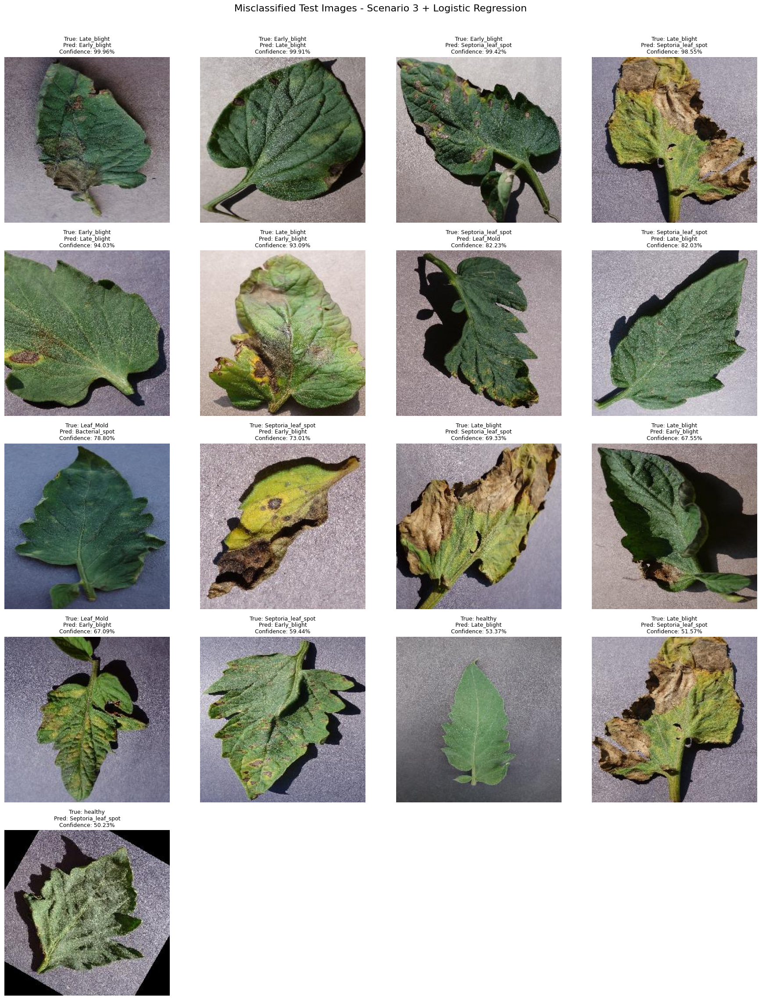


Misclassification analysis saved to:
/kaggle/working/plant_disease_results/final_test_misclassified_images.csv


In [39]:

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# =====================================
# 1. Get Test Metadata
# =====================================

test_metadata = metadata.loc[test_mask].reset_index(drop=True)

# Verify alignment
assert len(test_metadata) == len(y_test_final)
assert len(y_test_pred) == len(y_test_final)

# =====================================
# 2. Identify Misclassified Images
# =====================================

misclassified_indices = np.where(
    y_test_final != y_test_pred
)[0]

print("Total test images:", len(y_test_final))
print("Correct predictions:", np.sum(y_test_final == y_test_pred))
print("Misclassified images:", len(misclassified_indices))

# =====================================
# 3. Calculate Prediction Confidence
# =====================================

test_probabilities = final_model.predict_proba(X_test_final)

misclassified_data = []

for idx in misclassified_indices:

    true_label = int(y_test_final[idx])
    predicted_label = int(y_test_pred[idx])

    confidence = test_probabilities[idx, predicted_label]
    true_class_probability = test_probabilities[idx, true_label]

    image_path = test_metadata.loc[idx, "path"]

    misclassified_data.append({
        "Test_Index": idx,
        "Image_Path": image_path,
        "True_Label": true_label,
        "True_Class": idx_to_class[true_label],
        "Predicted_Label": predicted_label,
        "Predicted_Class": idx_to_class[predicted_label],
        "Prediction_Confidence": confidence,
        "True_Class_Probability": true_class_probability
    })

misclassified_df = pd.DataFrame(misclassified_data)

# Sort by prediction confidence
misclassified_df = misclassified_df.sort_values(
    "Prediction_Confidence",
    ascending=False
).reset_index(drop=True)

# =====================================
# 4. Display Error Summary
# =====================================

display(
    misclassified_df[
        [
            "Test_Index",
            "True_Class",
            "Predicted_Class",
            "Prediction_Confidence",
            "True_Class_Probability"
        ]
    ].style.format({
        "Prediction_Confidence": "{:.2%}",
        "True_Class_Probability": "{:.2%}"
    })
)

# =====================================
# 5. Display Misclassified Images
# =====================================

n_images = len(misclassified_df)
n_cols = 4
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 4.5)
)

axes = np.array(axes).reshape(-1)

for plot_idx, row in misclassified_df.iterrows():

    ax = axes[plot_idx]

    image_path = row["Image_Path"]

    try:
        img = Image.open(image_path).convert("RGB")

        ax.imshow(img)

        ax.set_title(
            f"True: {row['True_Class'].replace('Tomato___', '')}\n"
            f"Pred: {row['Predicted_Class'].replace('Tomato___', '')}\n"
            f"Confidence: {row['Prediction_Confidence']:.2%}",
            fontsize=9
        )

    except Exception as e:
        ax.text(
            0.5, 0.5,
            f"Image loading error:\n{e}",
            ha="center",
            va="center"
        )

    ax.axis("off")

# Hide unused axes
for idx in range(n_images, len(axes)):
    axes[idx].axis("off")

plt.suptitle(
    "Misclassified Test Images - Scenario 3 + Logistic Regression",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

# =====================================
# 6. Save Misclassification Analysis
# =====================================

output_path = os.path.join(
    results_dir,
    "final_test_misclassified_images.csv"
)

misclassified_df.to_csv(output_path, index=False)

print("\nMisclassification analysis saved to:")
print(output_path)


Image saved successfully:
/kaggle/working/plant_disease_results/high_confidence_misclassified_images.png


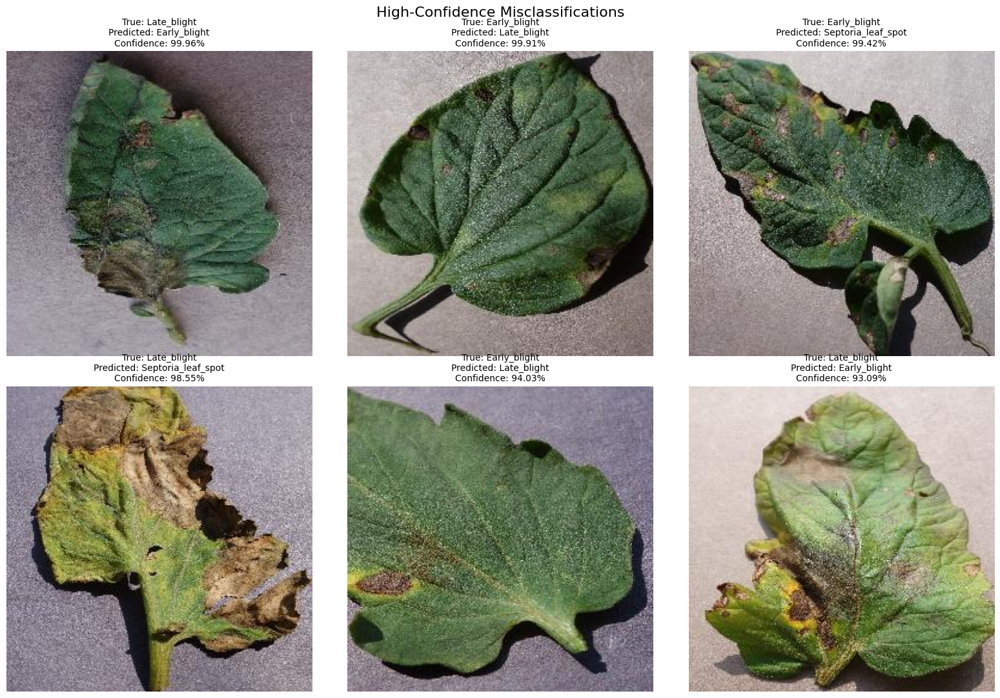

Images inspected: 6


In [41]:

# Inspect the 6 highest-confidence misclassifications

high_conf_errors = misclassified_df[
    misclassified_df["Prediction_Confidence"] >= 0.90
].copy()

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.flatten()

for i, (_, row) in enumerate(high_conf_errors.iterrows()):

    img = Image.open(row["Image_Path"]).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(
        f"True: {row['True_Class'].replace('Tomato___', '')}\n"
        f"Predicted: {row['Predicted_Class'].replace('Tomato___', '')}\n"
        f"Confidence: {row['Prediction_Confidence']:.2%}",
        fontsize=10
    )
    axes[i].axis("off")

plt.suptitle(
    "High-Confidence Misclassifications",
    fontsize=16
)

plt.tight_layout()
# Save the six high-confidence error images
output_image_path = os.path.join(
    results_dir,
    "high_confidence_misclassified_images.png"
)

plt.savefig(
    output_image_path,
    dpi=200,
    bbox_inches="tight"
)

print("Image saved successfully:")
print(output_image_path)
plt.show()

print("Images inspected:", len(high_conf_errors))


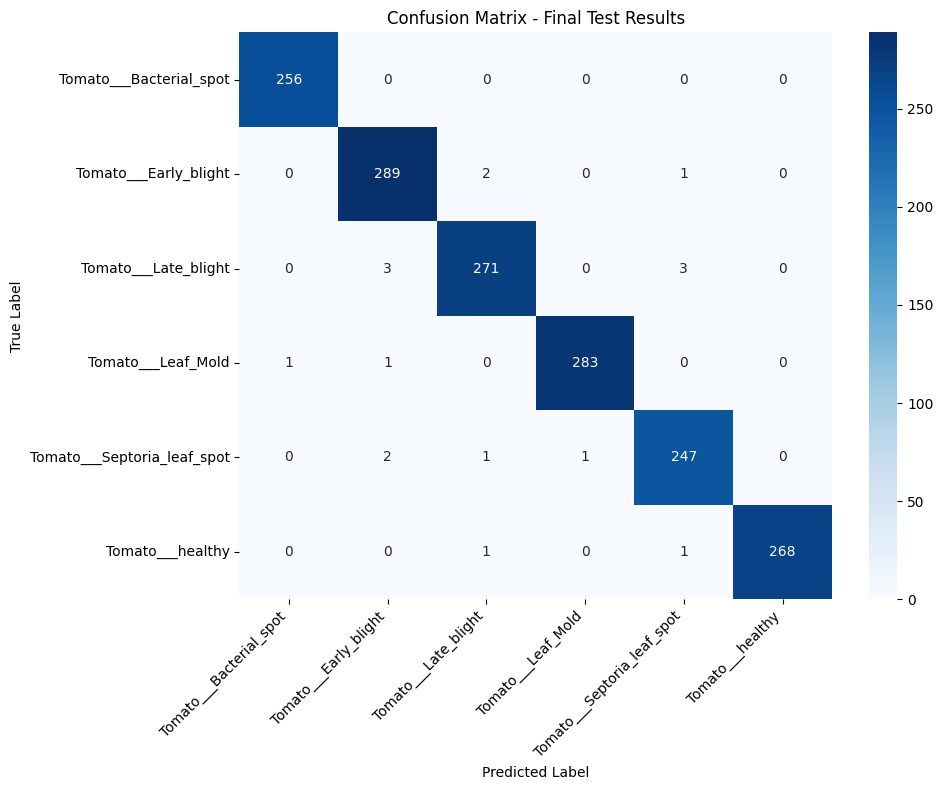

Confusion Matrix saved at: /kaggle/working/plant_disease_results/final_test_confusion_matrix.png


In [42]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix using existing test predictions
cm = confusion_matrix(y_test_final, y_test_pred)

# Create figure
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Final Test Results")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save image
save_path = os.path.join(
    results_dir,
    "final_test_confusion_matrix.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print(f"Confusion Matrix saved at: {save_path}")